# Notebook 2 — Solutions to the exercises

Model solutions for instructors and self-learners. Try the exercises in `notebooks/02_undersampling_and_aliasing.ipynb` first.

## Setup (same as Notebook 2)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import shepp_logan_phantom
from skimage.transform import resize

plt.rcParams["figure.dpi"] = 100
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # line colors, always used in this order

In [2]:
# ---- From Notebook 1 -------------------------------------------------------
def fft2c(image):
    """Centered, orthonormal 2D FFT: image -> k-space."""
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(image), norm="ortho"))


def ifft2c(kspace):
    """Centered, orthonormal inverse 2D FFT: k-space -> image."""
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kspace), norm="ortho"))


def show(images, titles, cmap="gray", vmin=None, vmax=None):
    """Show images side by side."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.6))
    for ax, im, title in zip(np.atleast_1d(axes), images, titles):
        ax.set_title(title)
        if im.dtype == bool:  # sampling masks: white = measured, black = skipped, with a thin frame
            ax.imshow(im, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
        else:
            ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


# ---- New in this notebook ----------------------------------------------------
def nrmse(recon, reference):
    """Normalized root-mean-square error: 0 is perfect, 1 is as large as the image itself."""
    return np.linalg.norm(recon - reference) / np.linalg.norm(reference)


def tidy(ax):
    """Quiet grid and axes for line plots."""
    ax.grid(alpha=0.25, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)


# ---- The object and its fully sampled k-space ----------------------------------
N = 256
image = resize(shepp_logan_phantom(), (N, N), anti_aliasing=True)
kspace = fft2c(image)
print(f"Ground truth: {N} x {N} phantom; full k-space has {N} phase-encode lines")

Ground truth: 256 x 256 phantom; full k-space has 256 phase-encode lines


In [3]:
def regular_lines(N, R):
    """Every R-th phase-encode line, always including the center line."""
    lines = np.zeros(N, dtype=bool)
    lines[(N // 2) % R :: R] = True
    return lines


def random_lines(N, R, center_fraction=0.0, seed=0):
    """N // R lines: a fully sampled central block, the rest chosen uniformly at random."""
    rng = np.random.default_rng(seed)
    n_total = N // R
    n_center = int(round(N * center_fraction))
    lines = np.zeros(N, dtype=bool)
    lines[N // 2 - n_center // 2 : N // 2 - n_center // 2 + n_center] = True
    candidates = np.flatnonzero(~lines)
    lines[rng.choice(candidates, size=n_total - n_center, replace=False)] = True
    return lines


def variable_density_lines(N, R, center_fraction=0.08, decay=3, seed=0):
    """N // R lines: a fully sampled center, the rest chosen at random,
    with lines near the center much more likely to be picked than lines near the edge."""
    rng = np.random.default_rng(seed)
    n_total = N // R
    n_center = int(round(N * center_fraction))
    lines = np.zeros(N, dtype=bool)
    lines[N // 2 - n_center // 2 : N // 2 - n_center // 2 + n_center] = True
    candidates = np.flatnonzero(~lines)
    distance = np.abs(candidates - N // 2) / (N / 2)       # 0 at the center, 1 at the edge
    probability = (1 - distance) ** decay + 1e-6
    lines[rng.choice(candidates, size=n_total - n_center, replace=False,
                     p=probability / probability.sum())] = True
    return lines


def as_mask(lines):
    """Turn a 1D set of phase-encode lines into a 2D k-space mask (each line covers every column)."""
    return np.repeat(lines[:, None], lines.size, axis=1)


def zero_filled(kspace, lines):
    """Simplest reconstruction: treat unmeasured k-space as zero and apply the inverse FFT."""
    return np.abs(ifft2c(kspace * lines[:, None]))

## Exercise 1: the wrong direction

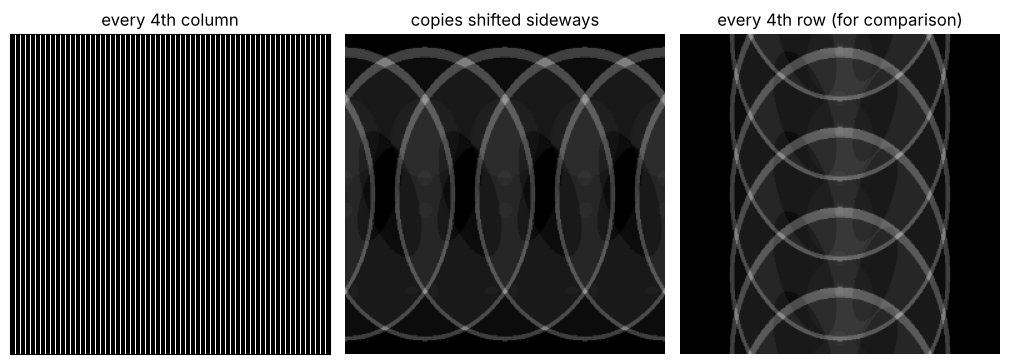

In [4]:
quarter = regular_lines(N, 4)
column_recon = np.abs(ifft2c(kspace * quarter[None, :]))
row_recon = zero_filled(kspace, quarter)

show([as_mask(quarter).T, column_recon, row_recon],
     ["every 4th column", "copies shifted sideways", "every 4th row (for comparison)"],
     vmin=0, vmax=1)

The copies now appear **horizontally**: aliasing always happens along the direction that was undersampled. Real scanners never accelerate along the readout direction because a whole row is recorded within one repetition in a few milliseconds. Skipping columns would save essentially no scan time, while skipping rows saves whole repetitions.

## Exercise 2: how big should the center be?

center fraction 0.00 ( 0 lines): NRMSE = 0.402
center fraction 0.02 ( 5 lines): NRMSE = 0.373
center fraction 0.04 (10 lines): NRMSE = 0.351
center fraction 0.08 (20 lines): NRMSE = 0.293
center fraction 0.16 (41 lines): NRMSE = 0.232
center fraction 0.24 (61 lines): NRMSE = 0.205


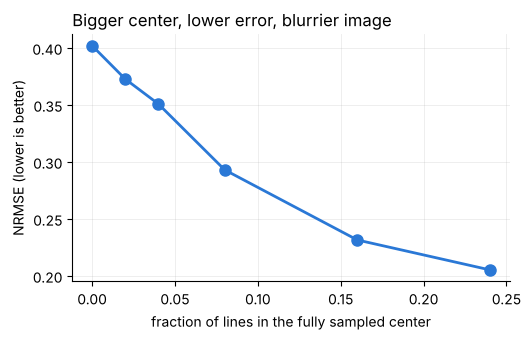

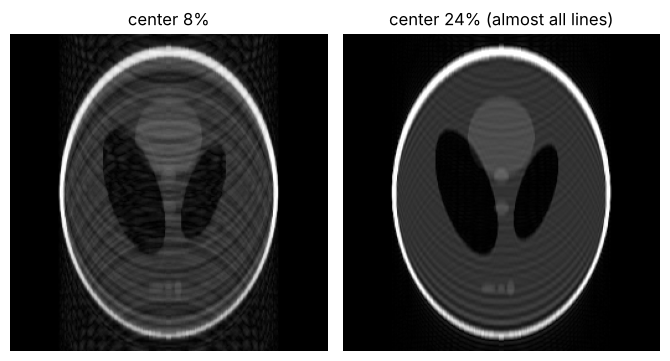

In [5]:
fractions = [0, 0.02, 0.04, 0.08, 0.16, 0.24]
errors = [nrmse(zero_filled(kspace, variable_density_lines(N, 4, center_fraction=f)), image) for f in fractions]

for f, e in zip(fractions, errors):
    print(f"center fraction {f:.2f} ({int(round(N * f)):>2} lines): NRMSE = {e:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(fractions, errors, "o-", color=COLORS[0], linewidth=2, markersize=8)
ax.set_xlabel("fraction of lines in the fully sampled center")
ax.set_ylabel("NRMSE (lower is better)")
ax.set_title("Bigger center, lower error, blurrier image", loc="left")
tidy(ax)
plt.tight_layout()
plt.show()

show([zero_filled(kspace, variable_density_lines(N, 4, center_fraction=f)) for f in [0.08, 0.24]],
     ["center 8%", "center 24% (almost all lines)"], vmin=0, vmax=1)

**Surprise:** the error keeps falling as the center grows. At 24%, almost all 64 lines are in the center, so the result is simply a **low-resolution image** (Notebook 1, Section 6). It has no streaks and the lowest NRMSE, yet it is **blurry**: edges are soft and fine details, such as the three small ellipses near the bottom, are smeared.

So a bigger center is *not* always better: it trades fine detail for a smaller error. NRMSE averages over all pixels, so it rewards blur and barely notices a few lost small structures, which may be exactly what a radiologist needs to see. With zero-filling alone, there is no way around this trade-off. Reconstruction methods that remove noise-like artifacts (Notebooks 3 and 4) can keep more outer lines and still produce a clean image. Notebook 5 returns to the limits of error metrics.

## Exercise 3: the luck of the draw

In [6]:
seed_errors = np.array([
    nrmse(zero_filled(kspace, random_lines(N, 4, center_fraction=0.08, seed=s)), image)
    for s in range(20)
])
print(f"mean NRMSE {seed_errors.mean():.3f}, best {seed_errors.min():.3f}, worst {seed_errors.max():.3f}")
print(f"best seed: {seed_errors.argmin()}, worst seed: {seed_errors.argmax()}")

mean NRMSE 0.388, best 0.365, worst 0.402
best seed: 0, worst seed: 1


The result changes from seed to seed. Showing only the best seed would make a method look better than it is in practice, where the mask is fixed before the patient is scanned. Good papers report results over several masks, or fix the mask in advance and say so.

## Exercise 4: design challenge (one possible approach)

Section 6 variable density: NRMSE = 0.293
Best found: NRMSE = 0.205 with center_fraction=0.12, decay=8, seed=2


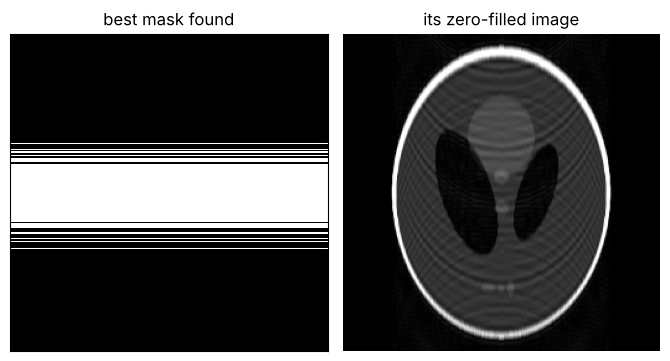

In [7]:
baseline = nrmse(zero_filled(kspace, variable_density_lines(N, 4)), image)

best = (np.inf, None)
for f in [0.04, 0.06, 0.08, 0.10, 0.12, 0.16]:
    for decay in [1, 2, 3, 4, 6, 8]:
        for seed in range(5):
            lines = variable_density_lines(N, 4, center_fraction=f, decay=decay, seed=seed)
            assert lines.sum() == 64
            e = nrmse(zero_filled(kspace, lines), image)
            if e < best[0]:
                best = (e, (f, decay, seed))

e, (f, decay, seed) = best
print(f"Section 6 variable density: NRMSE = {baseline:.3f}")
print(f"Best found: NRMSE = {e:.3f} with center_fraction={f}, decay={decay}, seed={seed}")
best_lines = variable_density_lines(N, 4, center_fraction=f, decay=decay, seed=seed)
show([as_mask(best_lines), zero_filled(kspace, best_lines)], ["best mask found", "its zero-filled image"], vmin=0, vmax=1)

The search finds a much lower error. But look at the mask: a strong decay puts almost every line near the center, so it is close to a **low-resolution scan**, just like the large center in Exercise 2. Lowest NRMSE here means "blurry but clean", not "best image". Two lessons for discussion:

1. **Know what your metric rewards.** For zero-filled reconstruction, NRMSE favors blur. Check the images, especially small structures, not only the number.
2. **Don't tune on your test image.** This mask was chosen using the ground truth of the same image it was tested on. In research, masks are tuned on training data and tested on separate images.

The best mask for compressed sensing or deep learning is different again: those methods can remove noise-like artifacts, so they benefit from keeping more random lines in the outer k-space.